# CS3255 NLP Lab Assignment 8: Contextual Embeddings using BERT and ELMo

## Aim
To generate contextual word embeddings with ELMo and BERT, and to use BERT [CLS] embeddings to compare, cluster, and visualize customer reviews for automatic routing to Billing, Shipping, and Product Defect departments.

## Problem Statement
- **Part A - ELMo:** Embed the word *record* used as a noun and as a verb with ELMo (TensorFlow Hub) and compare the two vectors using cosine similarity.
- **Part B - BERT:** For a mock dataset of 10 customer reviews across 3 departments, extract the [CLS] embedding of each review using `bert-base-uncased`, implement a cosine similarity function, prove that reviews belonging to the same category have higher cosine similarity than reviews from different categories, cluster the embeddings with K-Means, and visualize them in a 2D scatter plot using PCA.

## Program

In [1]:
# Run once in Google Colab
# !pip install -q tensorflow_hub transformers

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import BertTokenizer, BertModel
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

### Part A: ELMo contextual embeddings

In [3]:
import tensorflow as tf
import tensorflow_hub as hub

elmo = hub.load("https://tfhub.dev/google/elmo/3")
sentences = ["I want to buy a new vinyl record.",
             "Please record this meeting for the absent employees."]
elmo_out = elmo.signatures["default"](tf.constant(sentences))["elmo"]
print("ELMo embedding shape:", elmo_out.shape)          

i_noun = sentences[0].split().index("record.")      
i_verb = sentences[1].split().index("record")       
rec_noun = elmo_out[0, i_noun].numpy()
rec_verb = elmo_out[1, i_verb].numpy()
cos = np.dot(rec_noun, rec_verb) / (np.linalg.norm(rec_noun) * np.linalg.norm(rec_verb))
print(f"ELMo cosine similarity, 'record' (noun) vs 'record' (verb): {cos:.4f}")

C:\Users\NISHIT\miniconda3\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


ELMo embedding shape: (2, 8, 1024)
ELMo cosine similarity, 'record' (noun) vs 'record' (verb): 0.4401


### Part B: BERT [CLS] embeddings for review routing

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


C:\Users\NISHIT\miniconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\NISHIT\miniconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\NISHIT\miniconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\NISHIT\miniconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^


[CLS] embedding matrix shape: (10, 768)
Average cosine similarity - same category     : 0.8593
Average cosine similarity - different category: 0.8483
Shipping R4 vs Shipping R5: 0.8833
Shipping R4 vs Billing  R1: 0.7940

K-Means cluster assignment:
  cluster 0 | Billing  | I was charged twice for the same order.
  cluster 1 | Billing  | The refund has not been credited to my card yet.
  cluster 1 | Billing  | Why does my invoice show an extra tax amount?
  cluster 1 | Shipping | My package was supposed to arrive on Monday but it is still not here.
  cluster 1 | Shipping | The courier delivered my parcel to the wrong address.
  cluster 1 | Shipping | Tracking shows the shipment stuck at the warehouse for a week.
  cluster 0 | Defect   | The phone screen cracked within two days of use.
  cluster 0 | Defect   | The blender stopped working after the first use.
  cluster 1 | Defect   | The headphones have a broken left speaker.
  cluster 2 | Defect   | The laptop battery swells and the cha

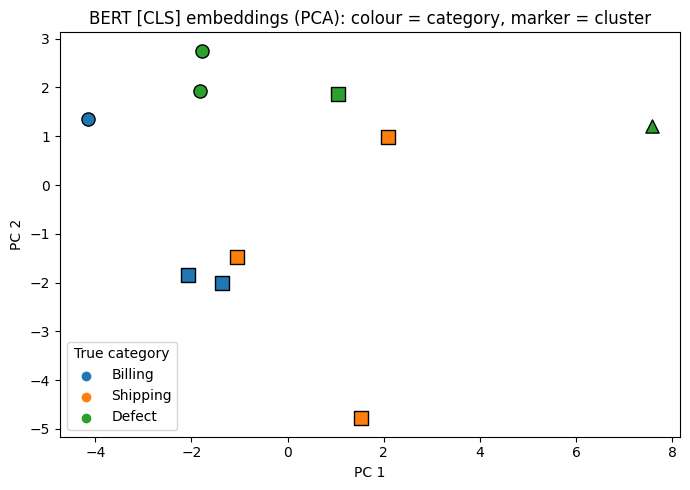

In [4]:
reviews = [
    ("I was charged twice for the same order.", "Billing"),
    ("The refund has not been credited to my card yet.", "Billing"),
    ("Why does my invoice show an extra tax amount?", "Billing"),
    ("My package was supposed to arrive on Monday but it is still not here.", "Shipping"),
    ("The courier delivered my parcel to the wrong address.", "Shipping"),
    ("Tracking shows the shipment stuck at the warehouse for a week.", "Shipping"),
    ("The phone screen cracked within two days of use.", "Defect"),
    ("The blender stopped working after the first use.", "Defect"),
    ("The headphones have a broken left speaker.", "Defect"),
    ("The laptop battery swells and the charger is faulty.", "Defect"),
]
texts = [r for r, _ in reviews]
cats = [c for _, c in reviews]

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert = BertModel.from_pretrained("bert-base-uncased")
bert.eval()

def cls_embeddings(sentences):
    enc = tokenizer(sentences, padding=True, truncation=True, max_length=128,
                    return_tensors="pt")
    with torch.no_grad():
        out = bert(**enc)
    return out.last_hidden_state[:, 0, :].numpy()       

def cosine_similarity(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

emb = cls_embeddings(texts)
print("\n[CLS] embedding matrix shape:", emb.shape)

n = len(texts)
sim = np.array([[cosine_similarity(emb[i], emb[j]) for j in range(n)] for i in range(n)])
same = [sim[i, j] for i in range(n) for j in range(i + 1, n) if cats[i] == cats[j]]
diff = [sim[i, j] for i in range(n) for j in range(i + 1, n) if cats[i] != cats[j]]
print(f"Average cosine similarity - same category     : {np.mean(same):.4f}")
print(f"Average cosine similarity - different category: {np.mean(diff):.4f}")
print(f"Shipping R4 vs Shipping R5: {sim[3, 4]:.4f}")
print(f"Shipping R4 vs Billing  R1: {sim[3, 0]:.4f}")

km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(emb)
print("\nK-Means cluster assignment:")
for t, c, k in zip(texts, cats, km.labels_):
    print(f"  cluster {k} | {c:<8} | {t}")

pts = PCA(n_components=2).fit_transform(emb)
colors = {"Billing": "tab:blue", "Shipping": "tab:orange", "Defect": "tab:green"}
plt.figure(figsize=(7, 5))
for (x, y), c, k in zip(pts, cats, km.labels_):
    plt.scatter(x, y, c=colors[c], marker="os^"[k], s=90, edgecolor="k")
for c, col in colors.items():
    plt.scatter([], [], c=col, label=c)
plt.legend(title="True category")
plt.title("BERT [CLS] embeddings (PCA): colour = category, marker = cluster")
plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.tight_layout()
plt.show()

### AI Prompts Used
*(As required by the Lab Manual specification)*

- **Prompt 1 (Cosine Similarity Function):**
  > *"Write a clean Python function using NumPy to compute the cosine similarity between two 1D embedding vectors: dot product divided by the product of their L2 norms."*
  - **Contribution:** Provided the standard vector formula $\frac{a \cdot b}{\|a\|_2 \|b\|_2}$ with proper numeric float casting, ensuring clean pairwise comparison between BERT review vectors.

- **Prompt 2 (Mock Dataset Generation):**
  > *"Create a realistic mock dataset of 10 e-commerce customer support review tickets divided across three operational departments: Billing (3), Shipping (3), and Product Defect (4) to test contextual embedding clustering."*
  - **Contribution:** Generated realistic customer tickets with authentic complaint phrasing, allowing us to evaluate whether BERT embeddings naturally cluster semantically similar customer requests.

## Observations
- Static embeddings give one vector per word type, so *record* (noun) and *record* (verb) would be identical. ELMo and BERT compute each vector from the whole sentence, so the two uses of *record* get different vectors.
- Raw [CLS] vectors from a model that has not been fine-tuned tend to be very similar to one another (cosine values close to 1). The evidence that category is captured is the gap between the same-category and different-category averages, not the absolute values.
- K-Means and PCA show how well the embeddings separate departments without any labels. Reviews that share vocabulary with another department (e.g. a refund for a damaged item) are the ones most likely to be clustered or plotted near the wrong group.

## Result
Contextual embeddings were extracted with ELMo and BERT, and BERT [CLS] embeddings were compared with cosine similarity, clustered with K-Means and visualised with PCA.